#### Business Question: Does the redesigned interface improve the user experience for both younger and older clients?
- Primary KPI: Average Time to Complete
- Supporting KPI: Completion Rate

##### H₀ — Time_improvement_50+ = Time_improvement_under50

##### H₁ — Time_improvement_50+ != Time_improvement_under50

### 1. Data prep

In [1]:
import pandas as pd

clients_demo = pd.read_csv('02_cleaned_data_files/cleaned_clients_demographics.csv')
clients_var = pd.read_csv('02_cleaned_data_files/cleaned_clients_variation.csv')
web_events = pd.read_csv('02_cleaned_data_files/cleaned_web_events.csv')

#### 1.1 — Inspect Datasets

In [2]:
# Check dataset sizes and column names
for name, df in {
    'Demographics': clients_demo,
    'Variation': clients_var,
    'Web Events': web_events
}.items():
    print(f'\n{name}: {df.shape}')
    print(df.columns.tolist())


Demographics: (50488, 9)
['client_id', 'clnt_tenure_yr', 'clnt_tenure_mnth', 'clnt_age', 'gendr', 'num_accts', 'bal', 'calls_6_mnth', 'logons_6_mnth']

Variation: (50488, 2)
['client_id', 'Variation']

Web Events: (317135, 5)
['client_id', 'visitor_id', 'visit_id', 'process_step', 'date_time']


#### 1.2 — Merge Datasets & Create Age Groups

In [3]:
# Merge web events with experiment groups and client ages
df = web_events.merge(clients_var, on='client_id', how='inner')
df = df.merge(clients_demo[['client_id', 'clnt_age']], on='client_id', how='inner')

# Convert timestamps to datetime
df['date_time'] = pd.to_datetime(df['date_time'])

# Split clients into two age groups
df['age_group'] = pd.cut(
    df['clnt_age'],
    bins=[0, 50, float('inf')],
    labels=['Under 50', '50+'],
    right=False
)

# Count unique clients in each experiment group
print(df.groupby(['age_group', 'Variation'])['client_id'].nunique())

age_group  Variation
Under 50   Control      12378
           Test         14494
50+        Control      11149
           Test         12467
Name: client_id, dtype: int64


#### 1.3 — Calculate Completion Time

In [4]:
# Get the first start time for each visit
starts = df[df['process_step'] == 'start'].groupby(
    ['client_id', 'visit_id']
)['date_time'].min().reset_index()

starts = starts.rename(columns={'date_time': 'start_time'})

# Get the first confirmation time for each visit
confirms = df[df['process_step'] == 'confirm'].groupby(
    ['client_id', 'visit_id']
)['date_time'].min().reset_index()

confirms = confirms.rename(columns={'date_time': 'confirm_time'})

# Keep visits with both start and confirm
completion = starts.merge(confirms, on=['client_id', 'visit_id'])

# Calculate completion time in seconds
completion['completion_time'] = (
    completion['confirm_time'] - completion['start_time']
).dt.total_seconds()

# Remove invalid completion times
completion = completion[completion['completion_time'] > 0]

# Check results
print(completion['completion_time'].describe())
print('Completed visits:', len(completion))

count    32849.000000
mean       382.122530
std        443.692461
min         32.000000
25%        158.000000
50%        254.000000
75%        436.000000
max      18015.000000
Name: completion_time, dtype: float64
Completed visits: 32849


#### 1.4 — Check Completion Time Quality

In [5]:
# Check unusually long completion times
print('Over 30 min:', (completion['completion_time'] > 1800).sum())
print('Over 60 min:', (completion['completion_time'] > 3600).sum())

# Check how many clients completed multiple visits
visits_per_client = completion.groupby('client_id')['visit_id'].nunique()

print('Unique clients:', completion['client_id'].nunique())
print('Clients with multiple visits:', (visits_per_client > 1).sum())

Over 30 min: 515
Over 60 min: 60
Unique clients: 32781
Clients with multiple visits: 63


#### 1.5 — Validate Start and Confirm Events

In [6]:
# Count start and confirm events per visit
start_counts = df[df['process_step'] == 'start'].groupby(
    ['client_id', 'visit_id']
).size()

confirm_counts = df[df['process_step'] == 'confirm'].groupby(
    ['client_id', 'visit_id']
).size()

# Check visits with repeated events
print('Repeated starts:', (start_counts > 1).sum())
print('Repeated confirms:', (confirm_counts > 1).sum())

Repeated starts: 20598
Repeated confirms: 3546


#### 1.6 — Inspect Repeated Events

In [7]:
# Add event counts to completed visits
check = completion.merge(
    start_counts.reset_index(name='starts'),
    on=['client_id', 'visit_id']
)

check = check.merge(
    confirm_counts.reset_index(name='confirms'),
    on=['client_id', 'visit_id']
)

# Check repeated events in completed visits
print('Repeated starts:', (check['starts'] > 1).sum())
print('Repeated confirms:', (check['confirms'] > 1).sum())

Repeated starts: 7419
Repeated confirms: 2495


In [8]:
# Select one completed visit with repeated starts
example = check[check['starts'] > 1][['client_id', 'visit_id']].head(1)

# Inspect the sequence of steps
df.merge(example, on=['client_id', 'visit_id'])[
    ['process_step', 'date_time']
].sort_values('date_time')

,process_step,date_time
9,start,2017-03-29 12:52:28
8,start,2017-03-29 12:52:48
7,start,2017-03-29 12:52:49
6,start,2017-03-29 12:54:05
5,step_1,2017-03-29 12:54:13
4,step_2,2017-03-29 12:54:26
3,step_3,2017-03-29 12:55:26
2,step_2,2017-03-29 12:55:28
1,step_3,2017-03-29 12:55:39
0,confirm,2017-03-29 12:55:56


#### 1.7 — Prepare Final Analysis Dataset

In [9]:
# Keep the first completed visit per client
analysis = completion.sort_values('confirm_time').drop_duplicates('client_id')

# Add experiment and age group information
analysis = analysis.merge(
    df[['client_id', 'Variation', 'age_group']].drop_duplicates(),
    on='client_id',
    how='left'
)

# Check final sample size
print('Clients:', len(analysis))

Clients: 32781


### 2. EDA — Completion Time Analysis

#### 2.1 — Compare Average Completion Time

In [10]:
# Compare completion time across age and experiment groups
time_summary = analysis.groupby(
    ['age_group', 'Variation']
)['completion_time'].agg(['count', 'mean', 'median']).round(1)

print(time_summary)

                     count   mean  median
age_group Variation                      
Under 50  Control     8125  332.7   231.0
          Test       10000  313.0   202.0
50+       Control     6774  461.7   326.0
          Test        7882  453.6   294.0


#### 2.2 — Calculate Time Improvement

In [11]:
# Get average completion time for each group
young_control = time_summary.loc[('Under 50', 'Control'), 'mean']
young_test = time_summary.loc[('Under 50', 'Test'), 'mean']

older_control = time_summary.loc[('50+', 'Control'), 'mean']
older_test = time_summary.loc[('50+', 'Test'), 'mean']

# Calculate absolute and relative improvement
young_improvement = young_control - young_test
older_improvement = older_control - older_test

print(f'Under 50: {young_improvement:.1f} sec ({young_improvement / young_control * 100:.1f}%)')
print(f'50+: {older_improvement:.1f} sec ({older_improvement / older_control * 100:.1f}%)')

Under 50: 19.7 sec (5.9%)
50+: 8.1 sec (1.8%)


#### 2.3 — Visualize Completion Time

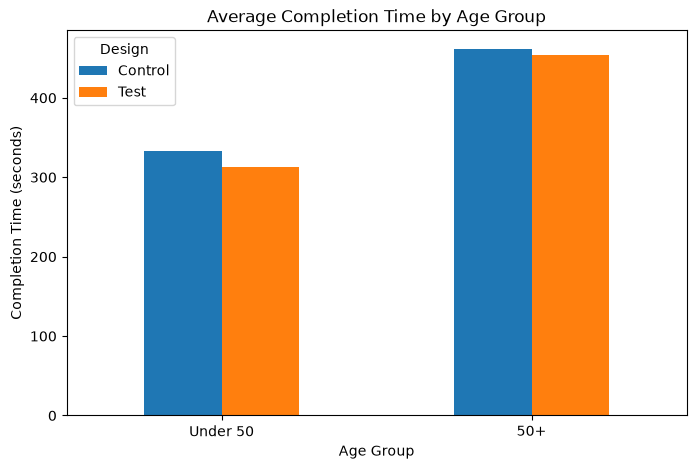

In [12]:
import matplotlib.pyplot as plt

# Compare average completion time across groups
time_summary['mean'].unstack().plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title('Average Completion Time by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Completion Time (seconds)')
plt.xticks(rotation=0)
plt.legend(title='Design')
plt.show()

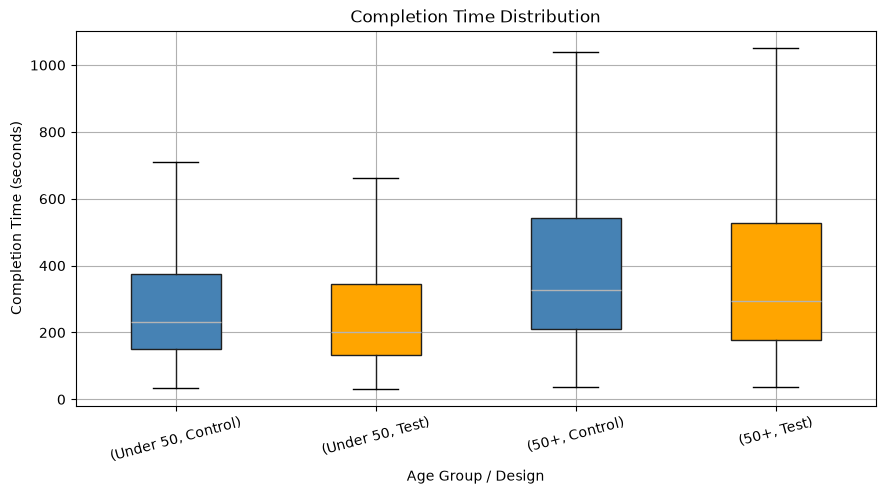

In [13]:
# Compare completion time distributions
ax = analysis.boxplot(
    column='completion_time',
    by=['age_group', 'Variation'],
    figsize=(10, 5),
    showfliers=False,
    patch_artist=True
)

# Color Control blue and Test orange
colors = ['steelblue', 'orange', 'steelblue', 'orange']

for box, color in zip(ax.patches, colors):
    box.set_facecolor(color)

plt.title('Completion Time Distribution')
plt.suptitle('')
plt.xlabel('Age Group / Design')
plt.ylabel('Completion Time (seconds)')
plt.xticks(rotation=15)
plt.show()

### 3. Hypothesis Testing

##### 3.1 — Test Completion Time Improvement
- H₀: Mean Time (Control) = Mean Time (Test)
- H₁: Mean Time (Control) ≠ Mean Time (Test)

In [14]:
import scipy.stats as st

# Split completion times into four groups
young_control = analysis[(analysis['age_group'] == 'Under 50') & (analysis['Variation'] == 'Control')]['completion_time']
young_test = analysis[(analysis['age_group'] == 'Under 50') & (analysis['Variation'] == 'Test')]['completion_time']

older_control = analysis[(analysis['age_group'] == '50+') & (analysis['Variation'] == 'Control')]['completion_time']
older_test = analysis[(analysis['age_group'] == '50+') & (analysis['Variation'] == 'Test')]['completion_time']

# Check standard deviations before testing
print('Under 50 STD:', young_control.std(), young_test.std())
print('50+ STD:', older_control.std(), older_test.std())

Under 50 STD: 343.2719100946523 405.2343580651641
50+ STD: 491.0732161745418 513.2883664678479


#### 3.2 — Independent T-Test

In [15]:
# Test Control vs Test for each age group
t_young, p_young = st.ttest_ind(young_control, young_test)
t_older, p_older = st.ttest_ind(older_control, older_test)

# Display p-values
print(f'Under 50 p-value: {p_young:.6f}')
print(f'50+ p-value: {p_older:.6f}')

Under 50 p-value: 0.000503
50+ p-value: 0.335376


#### 3.3 — Interpret T-Test Results

In [16]:
# Create a summary table
summary = pd.DataFrame({
    "Metric": [
        "Time Improvement",
        "Relative Improvement",
        "P-value",
        "Statistically Significant?"
    ],
    "Under 50": ["-19.7 sec", "5.9%", "0.000503", "YES"],
    "50+": ["-8.1 sec", "1.8%", "0.335376", "NO"]
})

# Display the table
display(summary.set_index("Metric"))

,Under 50,50+
Metric,,
Time Improvement,-19.7 sec,-8.1 sec
Relative Improvement,5.9%,1.8%
P-value,0.000503,0.335376
Statistically Significant?,YES,NO


##### The redesign significantly reduces completion time for clients under 50, while the observed improvement for clients aged 50+ is not statistically significant.

#### 3.4 Main Hypothesis Testing (CLT)
- H0: improvement 50+ = improvement under 50
- H1: improvement 50+ != improvement under 50

In [17]:
# Calculate improvement for each age group
young_improvement = young_control.mean() - young_test.mean()
older_improvement = older_control.mean() - older_test.mean()

# Calculate the difference between improvements
difference = young_improvement - older_improvement

# Calculate standard error using CLT
se = (
    young_control.var() / len(young_control)
    + young_test.var() / len(young_test)
    + older_control.var() / len(older_control)
    + older_test.var() / len(older_test)
) ** 0.5

# Calculate Z-score and two-sided p-value
z_score = difference / se
p_value = 2 * (1 - st.norm.cdf(abs(z_score)))

# Display results
print(f'Difference in improvement: {difference:.2f} sec')
print(f'Z-score: {z_score:.3f}')
print(f'P-value: {p_value:.6f}')

Difference in improvement: 11.65 sec
Z-score: 1.166
P-value: 0.243811


##### Conclusion: The new interface reduced average completion time by 19.7 seconds for clients under 50 and by 8.1 seconds for clients aged 50+. However, the difference in improvement between the two age groups was not statistically significant (p = 0.244). Therefore, we found insufficient evidence that the redesign affects the two age groups differently.

### 4. Supporting KPI — Completion Rate

#### 4.1 — Calculate Completion Rate

In [18]:
# Get unique clients who started the process
started_clients = df[df['process_step'] == 'start'][
    ['client_id', 'age_group', 'Variation']
].drop_duplicates()

# Check if each client completed the process
started_clients['completed'] = started_clients['client_id'].isin(
    completion['client_id']
)

# Calculate completion rate by group
completion_summary = started_clients.groupby(
    ['age_group', 'Variation']
)['completed'].agg(['count', 'sum', 'mean'])

# Convert completion rate to percentage
completion_summary['completion_rate'] = (
    completion_summary['mean'] * 100
).round(2)

print(completion_summary[['count', 'sum', 'completion_rate']])

                     count    sum  completion_rate
age_group Variation                               
Under 50  Control    12313   8125            65.99
          Test       14400  10000            69.44
50+       Control    11079   6774            61.14
          Test       12272   7882            64.23


#### 4.2 — Completion Rate Significance Test
- H₀: Completion Rate (Control) = Completion Rate (Test)
- H₁: Completion Rate (Control) != Completion Rate (Test)

In [19]:
# Test completion rate differences for each age group
for age in ['Under 50', '50+']:

    # Create a table of completed and not completed clients
    group = started_clients[started_clients['age_group'] == age]
    table = pd.crosstab(group['Variation'], group['completed'])

    # Run Chi-Square test
    chi2, p_value, dof, expected = st.chi2_contingency(table)

    print(f'{age} p-value: {p_value:.6f}')

Under 50 p-value: 0.000000
50+ p-value: 0.000001


##### Conclusion: The redesigned interface significantly improved completion rates in both age groups (p < 0.05). Completion Rate increased by 3.45 percentage points for clients under 50 and 3.09 percentage points for clients aged 50+. These results suggest that the new design improves process completion for both younger and older clients.

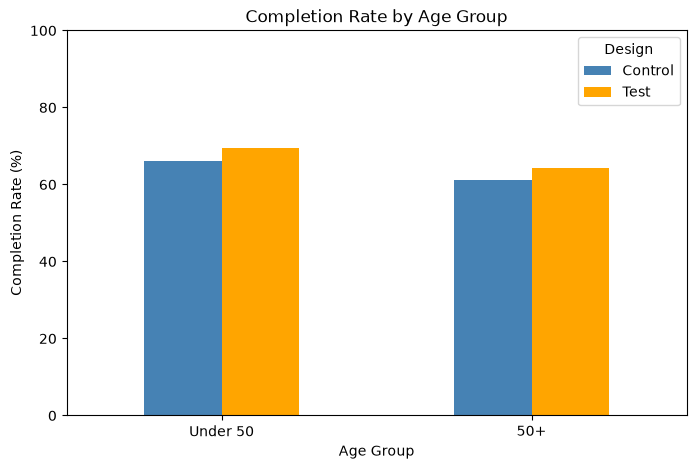

In [20]:
# Visualize completion rates by age group
completion_summary['completion_rate'].unstack().plot(
    kind='bar',
    figsize=(8, 5),
    color=['steelblue', 'orange']
)

plt.title('Completion Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Completion Rate (%)')
plt.ylim(0, 100)
plt.xticks(rotation=0)
plt.legend(title='Design')
plt.show()

### 5 — Final Business Conclusions
**5.1 — Hypothesis Result**

H₀: Time_improvement_50+ = Time_improvement_under50

H₁: Time_improvement_50+ ≠ Time_improvement_under50

Result: Fail to Reject H₀ (p = 0.2438)

There is insufficient statistical evidence that the redesign improves completion time differently for younger and older clients.

**5.2 — Statistical Significance**

Under 50: Average completion time decreased significantly by 19.7 seconds (p = 0.000503).

50+: Average completion time decreased by 8.1 seconds, but the improvement was not statistically significant (p = 0.3354).

Completion Rate: Increased significantly in both age groups (p < 0.05).

**5.3 — Business Impact**

1. Performance — Does the redesign improve process speed?

The new design reduced average completion time by 5.9% for Under 50 and 1.8% for 50+. However, only the improvement among younger clients was statistically significant.

2. Segment Impact — Who benefits more?

Younger clients showed a larger observed time improvement (11.65 seconds more), but the difference between age groups was not statistically significant.

Completion Rate increased by 3.45 percentage points for Under 50 and 3.09 percentage points for 50+, showing positive results in both segments.

3. Business Decision — Should Vanguard roll out the redesign?

The results support a monitored rollout of the redesigned interface, as completion rates improved significantly for both age groups.

However, Vanguard should continue monitoring completion times and investigate potential usability barriers for clients aged 50+.